### Employee Turnover Analysis

In [16]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, LabelEncoder

In [33]:
csv = pd.read_csv(r'B:\Project-git\employee-ml-analysis\HR_comma_sep.csv')
df = pd.DataFrame(csv)

data quality checks by checking for missing values, if any.

In [34]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 14999 entries, 0 to 14998
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   satisfaction_level     14999 non-null  float64
 1   last_evaluation        14999 non-null  float64
 2   number_project         14999 non-null  int64  
 3   average_montly_hours   14999 non-null  int64  
 4   time_spend_company     14999 non-null  int64  
 5   Work_accident          14999 non-null  int64  
 6   left                   14999 non-null  int64  
 7   promotion_last_5years  14999 non-null  int64  
 8   sales                  14999 non-null  str    
 9   salary                 14999 non-null  str    
dtypes: float64(2), int64(6), str(2)
memory usage: 1.1 MB


In [35]:
df.isna().sum()

satisfaction_level       0
last_evaluation          0
number_project           0
average_montly_hours     0
time_spend_company       0
Work_accident            0
left                     0
promotion_last_5years    0
sales                    0
salary                   0
dtype: int64

In [36]:
df.describe()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years
count,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000
mean,0.612834,0.716102,3.803054,201.050337,3.498233,0.144610,0.238083,0.021268
std,0.248631,0.171169,1.232592,49.943099,1.460136,0.351719,0.425924,0.144281
min,0.090000,0.360000,2.000000,96.000000,2.000000,0.000000,0.000000,0.000000
25%,0.440000,0.560000,3.000000,156.000000,3.000000,0.000000,0.000000,0.000000
50%,0.640000,0.720000,4.000000,200.000000,3.000000,0.000000,0.000000,0.000000
75%,0.820000,0.870000,5.000000,245.000000,4.000000,0.000000,0.000000,0.000000
max,1.000000,1.000000,7.000000,310.000000,10.000000,1.000000,1.000000,1.000000


In [37]:
df.drop_duplicates(inplace=True)

In [38]:
df["salary"].value_counts()

salary
low       5740
medium    5261
high       990
Name: count, dtype: int64

### what factors contributed most to employee turnover

LabelEncoder implemented on [salary] & [sales]

In [39]:
df["salary"] = LabelEncoder().fit_transform(df["salary"])
'''
0 - high
1 - low
2 - medium
'''

'\n0 - high\n1 - low\n2 - medium\n'

In [ ]:
df['time_spend_company'].value_counts()

0         3
1         6
2         4
3         5
4         3
         ..
11995    10
11996    10
11997    10
11998    10
11999     3
Name: time_spend_company, Length: 11991, dtype: int64

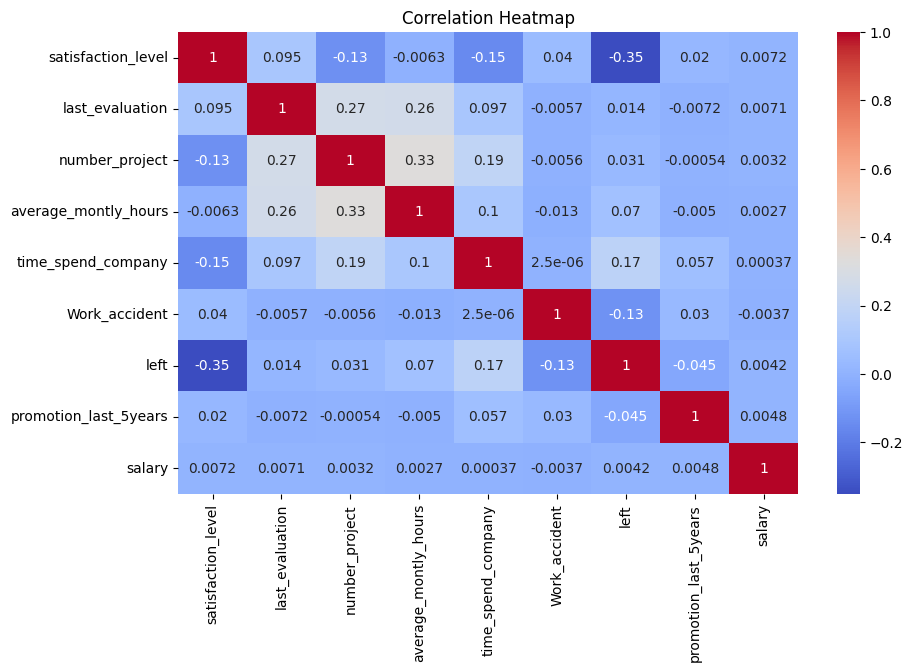

In [42]:
plt.figure(figsize=(10, 6))
sns.heatmap(df.drop(columns=['sales']).corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()